## Semiconductor Lab B7 - Task 1

Measure the I-U and P-I characteristics of the given laser diode in forward direction up to
100 mA. Give a statement about the quality of the contacts. Determine the threshold
current, the differential efficiency and the total efficiency of the laser diode.

In [1]:
%matplotlib inline

from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
from scipy import constants
from scipy.optimize import curve_fit

from b7.python.config import DATA_DIR, DOUBLE_COLUMN, PLOTS_DIR, SINGLE_COLUMN
from b7.python.helper import enrich_data_frame, pt_temperature

In [2]:
data_dir: Path = DATA_DIR / "task_1_2"
export_dir: Path = PLOTS_DIR

In [3]:
PT100_RESISTANCE = 108.48
TEMPERATURE: float = 273.15 + pt_temperature(PT100_RESISTANCE)
V_T: float = constants.k * TEMPERATURE / constants.e


def lasing_branch(I: npt.NDArray[np.float64], m: float, I_th: float) -> npt.NDArray[np.float64]:
    """Optical output power above threshold: linear in I, reaching zero at I_th."""
    return m * (I - I_th)


def ohmic_branch(I: npt.NDArray[np.float64], R_s: float, V_0: float) -> npt.NDArray[np.float64]:
    """Diode voltage above threshold.

    Gain clamping pins the junction voltage once the laser oscillates, so the only part
    of V_D that still follows the current is the drop over the series resistance.
    """
    return R_s * I + V_0


def diode_law(I: npt.NDArray[np.float64], n: float, log_I_0: float, R_s: float) -> npt.NDArray[np.float64]:
    """Diode voltage below threshold: ideal diode law plus the series resistance drop.

    I_0 enters as its decadic logarithm so that all three parameters stay comparable in
    size. Inverting the diode law makes V the dependent variable, which is what allows
    the series resistance to be fitted here at all.
    """
    return n * V_T * np.log(I / 10**log_I_0 + 1) + I * R_s

pprint({
    "PT100 Resistance Temperature": TEMPERATURE,
    "PT100 Resistance Temperature (°C)": TEMPERATURE - 273.15
})

{'PT100 Resistance Temperature': 294.91742612778745,
 'PT100 Resistance Temperature (°C)': 21.767426127787473}


### Import Data

In [4]:
file_name = "Messdaten B7 - Raumtemperatur (108.48 Ohm).csv"
df: pd.DataFrame = pd.read_csv(data_dir / file_name)
df

,Diodenstrom I_D (mA),Diodenspannung V_D (mV),Optische Leistung P
0,0.09,1368,6.03 nW
1,0.21,1406,14.5 nW
2,0.31,1433,30.35 nW
3,0.40,1449,46.20 nW
4,0.50,1461,65.23 nW
5,0.61,1473,88.1 nW
6,0.72,1482,113.3 nW
7,0.80,1488,133.1 nW
8,0.90,1496,160.9 nW
9,0.99,1502,185.3 nW


### Enrich Data

#### DataFrame Enrichment

In [5]:
# Rename Columns
df_enriched: pd.DataFrame = enrich_data_frame(df)
df_enriched

,I,V,P_opt,P_el,I_mA,V_mV,P_opt_nW,P_opt_mW,eta_total,eta_total_percent
0,0.00009,1.368,6.030000e-09,0.000123,0.09,1368,6.03,0.000006,0.000049,0.004898
1,0.00021,1.406,1.450000e-08,0.000295,0.21,1406,14.50,0.000015,0.000049,0.004911
2,0.00031,1.433,3.035000e-08,0.000444,0.31,1433,30.35,0.000030,0.000068,0.006832
3,0.00040,1.449,4.620000e-08,0.000580,0.40,1449,46.20,0.000046,0.000080,0.007971
4,0.00050,1.461,6.523000e-08,0.000731,0.50,1461,65.23,0.000065,0.000089,0.008930
5,0.00061,1.473,8.810000e-08,0.000899,0.61,1473,88.10,0.000088,0.000098,0.009805
6,0.00072,1.482,1.133000e-07,0.001067,0.72,1482,113.30,0.000113,0.000106,0.010618
7,0.00080,1.488,1.331000e-07,0.001190,0.80,1488,133.10,0.000133,0.000112,0.011181
8,0.00090,1.496,1.609000e-07,0.001346,0.90,1496,160.90,0.000161,0.000120,0.011950
9,0.00099,1.502,1.853000e-07,0.001487,0.99,1502,185.30,0.000185,0.000125,0.012461


#### Linear Fit

In [6]:
mask: pd.Series[bool] = df_enriched["I_mA"] > 12.5
(m, I_th), cov = curve_fit(lasing_branch, df_enriched[mask]["I"], df_enriched[mask]["P_opt"])
fit_data = {"m": {"value": m, "delta": np.sqrt(cov[0, 0])}, "I_th": {"value": I_th, "delta": np.sqrt(cov[1, 1])}}
pprint(fit_data)

{'I_th': {'delta': np.float64(9.858568852879307e-06),
          'value': np.float64(0.012807662274353128)},
 'm': {'delta': np.float64(0.0003320383015021719),
       'value': np.float64(0.14635714286003673)}}


#### Series Resistance

In [7]:
# Above threshold dV/dI is the series resistance
ohmic_mask = df_enriched["I_mA"] >= 14
(R_s, V_0), cov_ohmic = curve_fit(ohmic_branch, df_enriched[ohmic_mask]["I"], df_enriched[ohmic_mask]["V"])

# Below threshold the diode law still holds, which yields the ideality factor and a
# second, independent value for R_s out of a disjoint current range.
diode_mask = df_enriched["I_mA"] <= 12
(n_ideality, log_I_0, R_s_diode), cov_diode = curve_fit(
    diode_law,
    df_enriched[diode_mask]["I"],
    df_enriched[diode_mask]["V"],
    p0=[2.0, -9.0, 10.0],
)

iv_fit_data = {
    "above_threshold": {
        "R_s": {"value": R_s, "delta": np.sqrt(cov_ohmic[0, 0])},
        "V_0": {"value": V_0, "delta": np.sqrt(cov_ohmic[1, 1])},
    },
    "below_threshold": {
        "n": {"value": n_ideality, "delta": np.sqrt(cov_diode[0, 0])},
        "I_0": {
            # delta of 10**x is 10**x * ln(10) * delta_x
            "value": 10**log_I_0,
            "delta": 10**log_I_0 * np.log(10) * np.sqrt(cov_diode[1, 1]),
        },
        "R_s": {"value": R_s_diode, "delta": np.sqrt(cov_diode[2, 2])},
    },
}
pprint(iv_fit_data)

{'above_threshold': {'R_s': {'delta': np.float64(0.07659859965244308),
                             'value': np.float64(9.53571429049416)},
                     'V_0': {'delta': np.float64(0.0013111568311369515),
                             'value': np.float64(1.6290357142042697)}},
 'below_threshold': {'I_0': {'delta': np.float64(9.707348776104488e-17),
                             'value': np.float64(2.5040296575415723e-16)},
                     'R_s': {'delta': np.float64(0.2573179508519804),
                             'value': np.float64(10.196052306735503)},
                     'n': {'delta': np.float64(0.027676845315960263),
                           'value': np.float64(2.021000634239194)}}}


#### Calculated Quantities

In [8]:
WAVELENGTH = 778e-9  # main lasing mode of the 19 mA spectrum, see task5.ipynb
eta_diff = fit_data["m"]["value"] * constants.e * WAVELENGTH / (constants.h * constants.c)
eta_diff_delta = fit_data["m"]["delta"] * constants.e * WAVELENGTH / (constants.h * constants.c)
calculated_data = {"eta_diff": {"value": eta_diff, "delta": eta_diff_delta}}

pprint(calculated_data)

{'eta_diff': {'delta': np.float64(0.00020835380785065892),
              'value': np.float64(0.09183900737678018)}}


#### Quasi-Fermi Level Splitting Above Threshold

Gain clamping pins the junction voltage once the laser oscillates, so the intercept $V_0$ of the
ohmic branch is the clamped junction voltage and $e V_0 = F_\mathrm{n} - F_\mathrm{p}$. The
Bernard-Duraffourg condition requires it to exceed the photon energy of the lasing mode.

In [9]:
photon_energy_eV: float = constants.h * constants.c / (WAVELENGTH * constants.e)
splitting_eV: float = iv_fit_data["above_threshold"]["V_0"]["value"]  # e V_0 in eV

pprint({
    "photon_energy_eV": photon_energy_eV,
    "quasi_fermi_splitting_eV": splitting_eV,
    "splitting_exceeds_photon_energy": splitting_eV > photon_energy_eV,
})

{'photon_energy_eV': 1.5936272292185123,
 'quasi_fermi_splitting_eV': np.float64(1.6290357142042697),
 'splitting_exceeds_photon_energy': np.True_}


### Plot Data

#### Preparation

In [10]:
# Fit line, sampled over the lasing branch
left_padding = 0.0005
I_plot = np.linspace(min(df_enriched["I"][mask]) - left_padding, max(df_enriched["I"][mask]), 100)
P_plot = lasing_branch(I_plot, m, I_th)

# I-V fit curves. Both models are V(I)
I_ohmic = np.linspace(df_enriched["I"][ohmic_mask].min(), df_enriched["I"][ohmic_mask].max(), 100)
I_ohmic_mA = I_ohmic * 1e3
V_ohmic = ohmic_branch(I_ohmic, R_s, V_0)

I_diode = np.geomspace(df_enriched["I"][diode_mask].min(), df_enriched["I"][diode_mask].max(), 200)
I_diode_mA = I_diode * 1e3
V_diode = diode_law(I_diode, n_ideality, log_I_0, R_s_diode)

# Milli-scaled quantities, so the plot cells carry no unit arithmetic
I_plot_mA = I_plot * 1e3
P_plot_mW = P_plot * 1e3
I_th_mA = fit_data["I_th"]["value"] * 1e3
I_th_delta_mA = fit_data["I_th"]["delta"] * 1e3

# Threshold annotation in siunitx compact form. The uncertainty is rounded to one
# significant digit and the value to that same decimal place, so 12.807662 +- 0.009859
# is written 12.81(1) rather than 12.808(10). Rounding first is what moves the decimal
# place when the leading digit carries over, as 0.0098... -> 0.01 does here.
I_th_delta_rounded = round(I_th_delta_mA, -int(np.floor(np.log10(I_th_delta_mA))))
I_th_digits = -int(np.floor(np.log10(I_th_delta_rounded)))
I_th_label = (
    rf"$I_\mathrm{{th}} = \qty{{{I_th_mA:.{I_th_digits}f}"
    rf"({I_th_delta_rounded * 10**I_th_digits:.0f})}}{{\milli\ampere}}$"
)

#### Main Plots

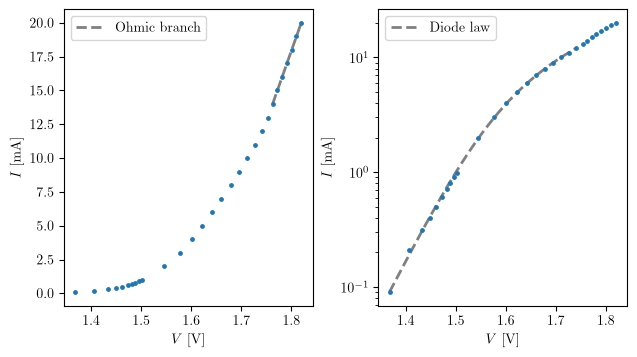

In [11]:
with plt.rc_context(DOUBLE_COLUMN):
    fig, (ax1, ax2) = plt.subplots(ncols=2, layout="constrained")

    ax1.scatter(df_enriched["V"], df_enriched["I_mA"], s=6)
    ax1.plot(V_ohmic, I_ohmic_mA, color="grey", zorder=-1, linestyle="--", label="Ohmic branch", lw=2)
    ax1.set_ylabel(r"$I$ [\unit{\milli \ampere}]")
    ax1.set_xlabel(r"$V$ [\unit{\volt}]")
    ax1.legend()

    ax2.scatter(df_enriched["V"], df_enriched["I_mA"], s=6)
    ax2.plot(V_diode, I_diode_mA, color="grey", zorder=-1, linestyle="--", label="Diode law", lw=2)
    ax2.set_yscale("log")
    ax2.set_ylabel(r"$I$ [\unit{\milli \ampere}]")
    ax2.set_xlabel(r"$V$ [\unit{\volt}]")
    ax2.legend()

    plt.savefig(export_dir / "task1_V_I.pdf")
    plt.show()

Caption:
Current voltage characteristics of the laser diode, in linear (left) and
logarithmic (right) scaling.

- Current-voltage characteristic curve was measured at temperature of 21°
- for low voltage, exponential shape of ideal diode is dominant
- for higher voltages, linear shape of series resistance becomes dominant
- two methods to determine the series resistance to evaluate contact quality:
  - Using ideal diode law with series resistance
    - fit in right plot
    - 10.2+-0.3
    - ideality factor of 2.02(3)
  - using ohms law for high voltage
    - fit in the left plot
    - 9.5 +- 0.1

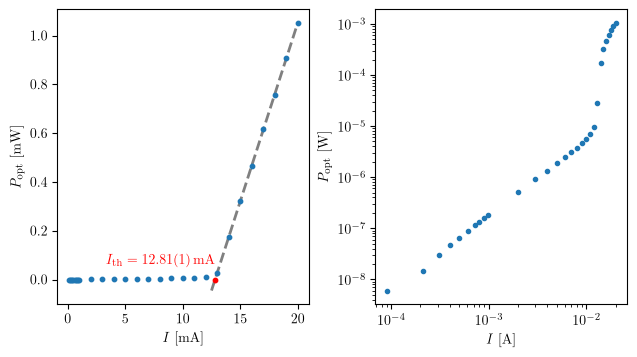

In [12]:
offset_right = 0.0035
offset_top = 0.05

with plt.rc_context(DOUBLE_COLUMN):
    fig, (ax1, ax2) = plt.subplots(ncols=2, layout="constrained")

    ax1.scatter(df_enriched["I_mA"], df_enriched["P_opt_mW"], s=10)
    ax1.plot(I_plot_mA, P_plot_mW, color="grey", zorder=-1, linestyle="--", lw=2)
    ax1.scatter(I_th_mA, 0, color="red", s=10)
    ax1.text(I_th_mA - offset_right, offset_top, s=I_th_label, va="bottom", ha="right", color="red")
    ax1.set_xlabel(r"$I$ [\unit{\milli\ampere}]")
    ax1.set_ylabel(r"$P_\mathrm{opt}$ [\unit{\milli\watt}]")

    ax2.scatter(df_enriched["I"], df_enriched["P_opt"], s=9)
    ax2.loglog()
    ax2.set_xlabel(r"$I$ [\unit{\ampere}]")
    ax2.set_ylabel(r"$P_\mathrm{opt}$ [\unit{\watt}]")

    plt.savefig(export_dir / "task1_I_P.pdf")
    plt.show()

Caption:
Power-current characteristics of the laser diode, in linear (left) and
logarithmic (right) scaling.

- power-current characteristics, measured at 21°C
- for low currents (up to $I_\mathrm{th}$, optical power is nearly zero
  - pn diode acts as an LED
  - no coherent light, large emission angle
  - detector only measures small fraction of the total output power
- for currents larger than $I_\mathrm{th}$, optical power rises sharpy
  - critical current density is reached, every additional current is
    used for stimulated emission, linear relationship
  - therefore, lasing starts, coherent light reaches the detector, resulting in
    linear relationship
  - narrow emission angle
  - the slope reads a differential efficiency of 9.44+-0.02 %


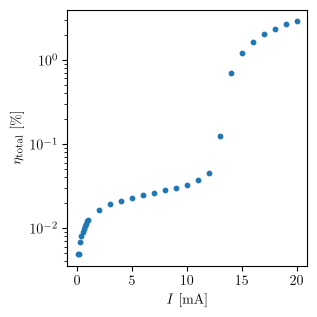

In [13]:
with plt.rc_context(SINGLE_COLUMN):
    fig, ax = plt.subplots(layout="constrained")
    ax.scatter(df_enriched["I_mA"], df_enriched["eta_total_percent"], s=10)
    ax.set_xlabel(r"$I$ [\unit{\milli\ampere}]")
    ax.set_ylabel(r"$\eta_\mathrm{total}$ [\unit{\percent}]")
    ax.set_yscale("log")

    plt.savefig(export_dir / "task1_I_eta.pdf")
    plt.show()